# Lab 02 — Decision trees and cross-validation

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Put Lectures 8 and 9 into code: learn a decision tree, measure it honestly, and choose its depth
**without looking at the test set**.

| # | Step | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Features, target, baseline | A1 | B1 |
| 2 | Train/test split, and check it | A2 | B2 |
| 3 | Entropy and information gain by hand | A3 | — |
| 4 | A fully grown tree: training error vs test error | A4–A5 | B3 |
| 5 | Error vs depth: underfitting and overfitting | A6 | B4 |
| 6 | Cross-validation, step by step, to choose the depth | A7 | B4–B5 |
| 7 | One final measure on the test set; read the tree | A8 | B6 |
| 8 | Data leakage: a tree that is too good | — | B7 |
| ★ | The Lab 1 recodings: does a tree need them? | — | B8 |

- **Part A (≈ 60 min)** — Iris: the experiment of Lecture 9, number by number.
- **Part B (≈ 45 min)** — NordicMart churn: the same workflow on the customer table of Lab 1.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices, as in Lab 1)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**: you may look at it only where the text says so.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports from scikit-learn: the tree, the tools to split the data, and cross-validation.

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 2.3.3


scikit-learn must be version **1.3 or later**: from 1.3 on, decision trees accept missing values (`NaN`), which we need in Part B.

# Part A — Iris

We use the copy of Iris shipped with scikit-learn: the same 150 flowers of Lab 1, with the classes coded as numbers
(0 = setosa, 1 = versicolor, 2 = virginica), as on the slides of Lectures 8 and 9.

## A1. Features, target, baseline

1. Load the data with `load_iris(as_frame=True)`: the result has the attributes `.data` (a DataFrame with the features)
   and `.target` (a Series with the class). Call them `X` and `y`.
1. Shorten the column names by removing the final `" (cm)"`, e.g. with a list comprehension `[c[:-5] for c in X.columns]`.
1. Print the shape of `X` and the class counts of `y`.
1. What is the accuracy of the *majority-class* baseline (Lecture 8)?

In [13]:
# Load Iris features and target
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()

X.columns = [c[:-5] for c in X.columns]

print("X shape:", X.shape)
print("y class counts:\n", y.value_counts())

# Majority-class baseline accuracy (predicting always the most frequent class)
baseline_acc = y.value_counts().max() / len(y)
print(f"\nMajority-class baseline accuracy: {baseline_acc:.3f} ({baseline_acc:.1%})")


X shape: (150, 4)
y class counts:
 target
0    50
1    50
2    50
Name: count, dtype: int64

Majority-class baseline accuracy: 0.333 (33.3%)


**Convention used in scikit-learn** (and in this course from now on): `X` is the table of features, one row per individual,
shape `(n_samples, n_features)`; `y` is the target, length `n_samples`. Every model has the same two methods:
`fit(X, y)` learns the parameters, `predict(X)` computes the class of new individuals.

## A2. Train/test split

Split Iris **50-50 at random** with [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html),
with `train_size=0.5` and `random_state=10` (the values of Lecture 9). Call the four results `X_train, X_test, y_train, y_test`.

Then check the split: size of the two parts, and class counts in each part.

**Question.** The original file is sorted by class (50 setosa, then 50 versicolor, then 50 virginica).
What would happen if we took the first 75 rows for training and the last 75 for testing?

In [14]:
# your code here
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size=0.5, random_state=10)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(75, 4)
(75, 4)
(75,)
(75,)


**Answer.** *Write your answer here (double-click to edit).*

## A3. Entropy and information gain, in code

### Entropy of a set of labels

Write a function `entropy(labels)` that receives a Series of class labels and returns
$H = -\sum_j p_j \log_2 p_j$, where $p_j$ are the class proportions.

- `labels.value_counts(normalize=True)` gives the proportions
- `np.log2` computes the base-2 logarithm, element by element
- classes with zero count do not appear in `value_counts`, so the convention $0 \log_2 0 = 0$ is automatic

Check it on the weather data of Lecture 8 (9 *yes*, 5 *no*: 0.940 bits), then compute the entropy of `y_train` and `y_test`.

In [15]:
# your code here
def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -(p* np.log2(p)).sum()

print(entropy(y_test))
print(entropy(y_train))

1.58188145993464
1.58188145993464


### Information gain of a threshold

Write a function `info_gain(x, labels, t)`: `x` is a numeric feature, `labels` the classes of the same rows,
`t` a threshold. It returns $IG = H(\text{labels}) - \big(H(\text{left})\,n_{left} + H(\text{right})\,n_{right}\big) / n$,
where *left* are the rows with `x < t` and *right* those with `x >= t`.
Use a **boolean mask**: `labels[x < t]` selects the labels of the rows where the condition is true.

Check: on the training set, the threshold 5.75 on `sepal length` must give a gain of 0.61 (Lecture 9).

In [16]:
# your code here
def info_gain(x, labels, t):
    left = labels[x<t]
    right = labels[x>=t]
    
    n = len(labels)
    n_left = len(left)
    n_right = len(right)
    h_labels = entropy(labels)
    
    h_left = entropy(left)
    h_right = entropy(right)
    
    return h_labels - (h_left*n_left + h_right*n_right)/n
    
print(info_gain(X_train["sepal length"], y_train, 5.75))


0.6097792066122029


### The best threshold of every attribute

The candidate thresholds of a numeric attribute are the **midpoints** between consecutive distinct values (Lecture 8).
Write a function `best_split(x, labels)` that tries all of them and returns the best threshold and its gain.
Hints: `np.sort(x.unique())` gives the distinct values in order; if `v` is that array, `(v[:-1] + v[1:]) / 2` are the midpoints.

Apply it to the four features of the training set and collect the results in a DataFrame.
Compare with the four frames *Predicting attribute* of Lecture 9.

In [17]:
# your code here
def best_split(x, labels):
    v = np.sort(x.unique())
    midpoints = (v[:-1] + v[1:]) / 2
    
    best_t = None
    best_ig = -1.0
    
    for t in midpoints:
        info = info_gain(x, labels, t)
        
        if info>best_ig:
            best_t = t
            best_ig = info
            
    return best_t

bestt = []

for col in X_train.columns:
    t = best_split(X_train[col], y_train)
    info = info_gain(X_train[col], y_train, t)
    
    bestt.append({"col": col, "best t": t, "info gain": info})
    
print(pd.DataFrame(bestt))
    
    
    


            col  best t  info gain
0  sepal length    5.75      0.610
1   sepal width    3.25      0.416
2  petal length    2.60      0.943
3   petal width    0.75      0.943


**Answer.** *Write your answer here (double-click to edit).*

### Information gain as a function of the threshold ★

Plot the gain of every candidate threshold of `petal width` (x axis: threshold, y axis: gain).
Why is the gain low at both ends?

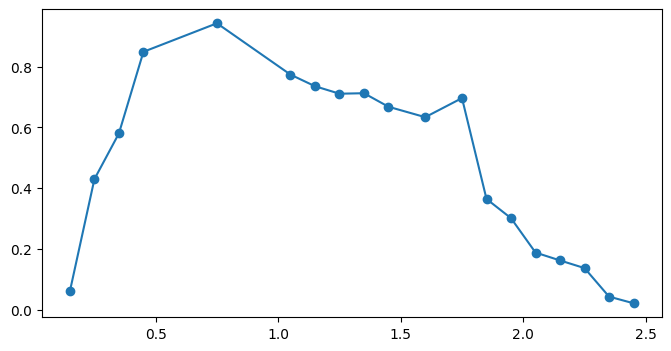

In [19]:
# your code here
v = np.sort(X_train["petal width"].unique())
midpoints = (v[:-1] + v[1:]) / 2

#A LA FUNCIÓN HAY QUE PASARLE TODOS, NO SOLO LOS ÚNICOS
gains = [info_gain(X_train["petal width"], y_train, t) for t in midpoints]

plt.plot(midpoints, gains, marker="o", color="tab:blue")



**Answer.**

The information gain is low at both ends because:

1. **Low thresholds (left end, $t \le 0.15$):** Almost all flowers fall to the right branch ($x \ge t$), leaving the left branch empty or with just 1 sample. The right branch inherits virtually the exact same class mixture and entropy as the root node, resulting in almost zero entropy reduction ($IG \approx 0$).
2. **High thresholds (right end, $t \ge 2.35$):** Symmetrically, almost all flowers fall to the left branch ($x < t$), leaving the right branch nearly empty. The left branch retains the parent node's entropy, again yielding negligible information gain.

Information gain peaks at interior thresholds where partitions separate substantial, pure subsets of classes: the global maximum at **0.75 cm** ($IG = 0.943$) perfectly isolates *setosa* from the other two classes, while the secondary peak around **1.75 cm** separates *versicolor* from *virginica*.

## A4. A fully grown tree on the original training set

1. Create a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
   with `criterion="entropy"` (the default is Gini, Lecture 9) and `random_state=10`, and learn it with `fit` on the training set.
   Without other hyperparameters, the tree grows until its leaves are pure.
1. Draw it with `plot_tree(model, feature_names=..., class_names=..., filled=True)`.
1. Print its depth (`get_depth()`) and number of leaves (`get_n_leaves()`).

[Text(0.3333333333333333, 0.9, 'petal width <= 0.75\nentropy = 1.582\nsamples = 75\nvalue = [27, 23, 25]\nclass = setosa'),
 Text(0.16666666666666666, 0.7, 'entropy = 0.0\nsamples = 27\nvalue = [27, 0, 0]\nclass = setosa'),
 Text(0.25, 0.8, 'True  '),
 Text(0.5, 0.7, 'petal length <= 4.75\nentropy = 0.999\nsamples = 48\nvalue = [0, 23, 25]\nclass = virginica'),
 Text(0.41666666666666663, 0.8, '  False'),
 Text(0.3333333333333333, 0.5, 'entropy = 0.0\nsamples = 22\nvalue = [0, 22, 0]\nclass = versicolor'),
 Text(0.6666666666666666, 0.5, 'petal width <= 1.75\nentropy = 0.235\nsamples = 26\nvalue = [0, 1, 25]\nclass = virginica'),
 Text(0.5, 0.3, 'petal width <= 1.6\nentropy = 0.811\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.3333333333333333, 0.1, 'entropy = 0.0\nsamples = 3\nvalue = [0, 0, 3]\nclass = virginica'),
 Text(0.6666666666666666, 0.1, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1, 0]\nclass = versicolor'),
 Text(0.8333333333333334, 0.3, 'entropy = 0.0\nsamples =

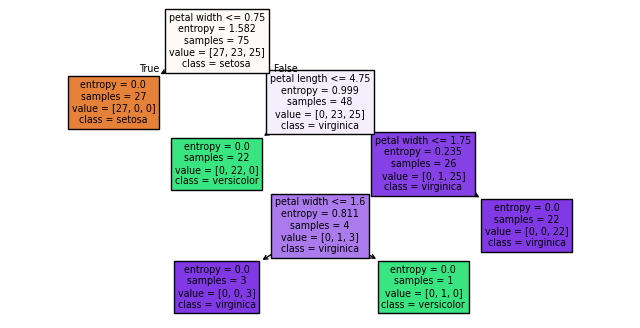

In [20]:
# your code here
model = DecisionTreeClassifier(criterion="entropy", random_state=10)
model.fit(X_train, y_train)

plot_tree(model, feature_names=X_train.columns, class_names=iris.target_names, filled=True)

### Training error and test error

Compute the predictions on the training set and on the test set, and for each one the **number of errors** and the **error rate**.

- `model.predict(X)` returns the predicted classes
- `(predicted != y).sum()` counts the errors; `accuracy_score(y, predicted)` gives the accuracy, and the error rate is 1 − accuracy
- `model.score(X, y)` computes the accuracy in one call

Since we will repeat this many times, write a small function `errors(model, X, y)` returning the number of errors.

In [27]:
def errors(model, X, y):
    predicted = model.predict(X)
    return (predicted != y).sum()

# 1. En Entrenamiento
err_train = errors(model, X_train, y_train)
acc_train = model.score(X_train, y_train)
print(f"Train -> Errores: {err_train} / {len(y_train)} | Tasa de error: {1 - acc_train:.1%} | Accuracy: {acc_train:.3f}")

# 2. En Test
err_test = errors(model, X_test, y_test)
acc_test = model.score(X_test, y_test)
print(f"Test  -> Errores: {err_test} / {len(y_test)} | Tasa de error: {1 - acc_test:.1%} | Accuracy: {acc_test:.3f}")


Train -> Errores: 0 / 75 | Tasa de error: 0.0% | Accuracy: 1.000
Test  -> Errores: 6 / 75 | Tasa de error: 8.0% | Accuracy: 0.920


**Answer.** *Write your answer here (double-click to edit).*

## A5. The altered training set of Lecture 9

To make noise and overfitting visible, Lecture 9 altered two training flowers:

- flower **125** (a virginica): label changed to 0 (setosa)
- flower **113** (a virginica): measurements overwritten with those of flower 125, label changed to 1 (versicolor)

1. Create the copies `X_train_alt` and `y_train_alt` (use `.copy()`: the original training set must stay untouched)
   and apply the two changes with `.loc[...]`: the numbers are row **labels** (the index of the original data set), not positions.
1. Check the class counts: Lecture 9 says 28/24/23.
1. Learn a fully grown tree `tree_alt` (same hyperparameters as before) on the altered set; draw it; count training and test errors.

In [28]:
# your code here
X_train_alt = X_train.copy()
y_train_alt = y_train.copy()

y_train_alt.loc[125] = 0

X_train_alt.loc[113] = X_train_alt.loc[125]
y_train_alt.loc[113] = 1


Train -> Errores: 1 / 75 | Tasa de error: 1.3% | Accuracy: 0.987
Test  -> Errores: 12 / 75 | Tasa de error: 16.0% | Accuracy: 0.840


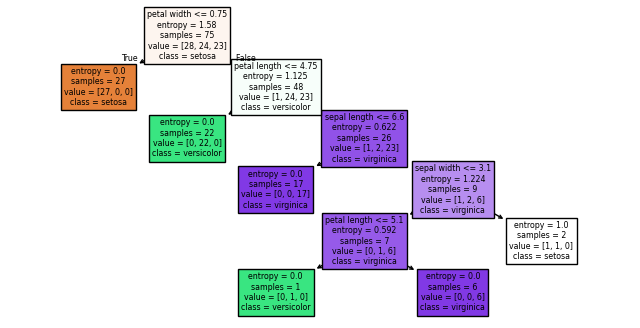

In [30]:
# your code here
model_alt = DecisionTreeClassifier(criterion="entropy", random_state=10)
model_alt.fit(X_train_alt, y_train_alt)

plot_tree(model_alt, feature_names=X_train_alt.columns, class_names=iris.target_names, filled=True)

# 1. En Entrenamiento
err_train_alt = errors(model_alt, X_train_alt, y_train_alt)
acc_train = model_alt.score(X_train_alt, y_train_alt)
print(f"Train -> Errores: {err_train_alt} / {len(y_train_alt)} | Tasa de error: {1 - acc_train:.1%} | Accuracy: {acc_train:.3f}")

# 2. En Test
err_test = errors(model_alt, X_test, y_test)
acc_test = model_alt.score(X_test, y_test)
print(f"Test  -> Errores: {err_test} / {len(y_test)} | Tasa de error: {1 - acc_test:.1%} | Accuracy: {acc_test:.3f}")


### Inside the tree: the arrays of `tree_`

The learned tree is stored in the attribute `tree_` as parallel arrays, one position per node (Lecture 9, *internal representation*):
`children_left`, `children_right` (−1 for a leaf), `feature` (index of the tested column), `threshold`,
`n_node_samples`, `impurity`.

1. Put these arrays into a DataFrame, one row per node; replace the feature index with the column name, and show
   `-` for feature and threshold in the leaves.
1. Which leaf is impure? Which training flowers reach it? `model.apply(X)` returns, for every row, the node (leaf) where it ends.

In [31]:
t = model_alt.tree_
cols = list(X_train_alt.columns)

df_tree = pd.DataFrame({
    "node": range(t.node_count),
    "left": t.children_left,
    "right": t.children_right,
    "feature": [cols[f] if f != -2 else "-" for f in t.feature],
    "threshold": [round(th, 3) if th != -2.0 else "-" for th in t.threshold],
    "n_samples": t.n_node_samples,
    "impurity": np.round(t.impurity, 3)
})

print(df_tree.to_string(index=False))


 node  left  right      feature threshold  n_samples  impurity
    0     1      2  petal width      0.75         75     1.580
    1    -1     -1            -         -         27     0.000
    2     3      4 petal length      4.75         48     1.125
    3    -1     -1            -         -         22     0.000
    4     5      6 sepal length       6.6         26     0.622
    5    -1     -1            -         -         17     0.000
    6     7     10  sepal width       3.1          9     1.224
    7     8      9 petal length       5.1          7     0.592
    8    -1     -1            -         -          1     0.000
    9    -1     -1            -         -          6     0.000
   10    -1     -1            -         -          2     1.000


In [32]:
# your code here
# 1. Localizar la hoja impura (nodo sin hijos y con impureza > 0)
is_leaf = df_tree["left"] == -1
impure_leaf = df_tree[is_leaf & (df_tree["impurity"] > 0)]
impure_node_id = impure_leaf["node"].values[0]

print(f"Hoja impura encontrada: Nodo {impure_node_id}")
print(impure_leaf[["node", "n_samples", "impurity"]].to_string(index=False))

# 2. Localizar qué flores del conjunto de entrenamiento caen en esa hoja
terminal_nodes = model_alt.apply(X_train_alt)
flowers_in_leaf = X_train_alt.index[terminal_nodes == impure_node_id]

print(f"\nFlores que alcanzan la hoja {impure_node_id}:", list(flowers_in_leaf))
print(y_train_alt.loc[flowers_in_leaf])

Hoja impura encontrada: Nodo 10
 node  n_samples  impurity
   10          2       1.0

Flores que alcanzan la hoja 10: [113, 125]
113    1
125    0
Name: target, dtype: int64


**Answer.** *Write your answer here (double-click to edit).*

## A6. Error vs depth: underfitting and overfitting

Learn trees on the **altered** training set with `max_depth` from 1 to 5. For each depth, record the training error rate
and the test error rate in a DataFrame, then plot the two curves (x: depth, y: error rate).
Compare with the figure *Errors and tree depth* of Lecture 9.


Árbol de profundidad 1: Train accuracy: 0.680 | Test accuracy: 0.667

Árbol de profundidad 2: Train accuracy: 0.960 | Test accuracy: 0.920

Árbol de profundidad 3: Train accuracy: 0.960 | Test accuracy: 0.920

Árbol de profundidad 4: Train accuracy: 0.973 | Test accuracy: 0.827

Árbol de profundidad 5: Train accuracy: 0.987 | Test accuracy: 0.840


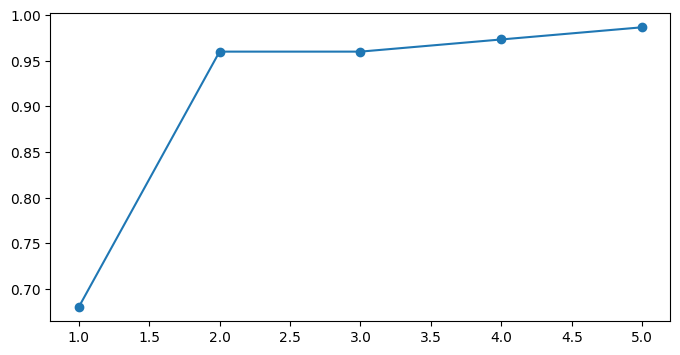

In [35]:
# your code here
trees = {}
for i in range(1, 6):
    trees[i] = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=i,
        random_state=10
    )
    trees[i].fit(X_train_alt, y_train_alt)
    
    print(f"\nÁrbol de profundidad {i}:", 
          f"Train accuracy: {trees[i].score(X_train_alt, y_train_alt):.3f} |",
          f"Test accuracy: {trees[i].score(X_test, y_test):.3f}")
    
plt.plot(range(1, 6), [trees[i].score(X_train_alt, y_train_alt) for i in range(1, 6)], marker="o", label="Train")



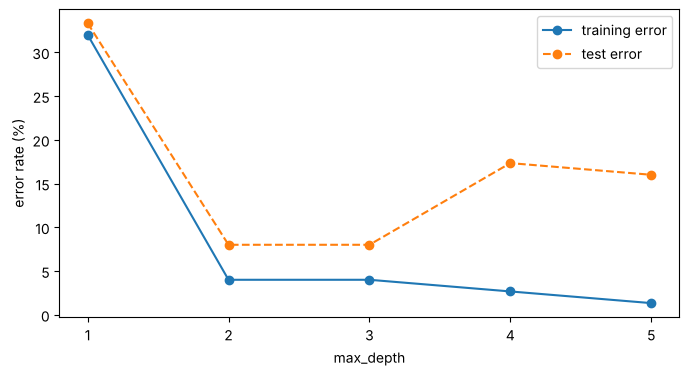

In [15]:
# your code here


**Question.** Where does the tree underfit, where does it overfit? Which depth would you choose?
And now the important question: **are you allowed to choose it this way?**

**Answer.** *Write your answer here (double-click to edit).*

## A7. Cross-validation, step by step

From now on the test set is **locked**. Everything happens on the 75 flowers of the (altered) training set.

### Step 1 — the folds

[`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
cuts the training set into $k$ folds keeping the class proportions in each fold (*stratified*, Lecture 8).
Create `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.

`cv.split(X, y)` produces, for each round, two arrays of **positions**: the rows used to learn and the rows held out.
Loop over the rounds with `enumerate`, and for each one print the number of rows of the two parts and the class counts
of the held-out fold. Use `.iloc` to select rows by position.

In [40]:
# Stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Iterate over folds, printing split sizes and class distribution in held-out part
for round_num, (train_idx, val_idx) in enumerate(cv.split(X_train_alt, y_train_alt), 1):
    val_labels = y_train_alt.iloc[val_idx]
    counts = dict(val_labels.value_counts().sort_index())
    print(f"Round {round_num}: Learn={len(train_idx)}, Held-out={len(val_idx)} | Held-out classes: {counts}")


Round 1: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(4), 2: np.int64(5)}
Round 2: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(5), 1: np.int64(5), 2: np.int64(5)}
Round 3: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(5), 1: np.int64(5), 2: np.int64(5)}
Round 4: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(5), 2: np.int64(4)}
Round 5: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(5), 2: np.int64(4)}


**Question.** How many times is each flower held out? How many times is it used for learning?

**Answer.**

In 5-fold cross-validation ($k = 5$):

- **Held out (validation):** Each flower is held out **exactly 1 time**. The 75 training samples are partitioned into 5 disjoint, non-overlapping folds of 15 flowers, so every sample serves as a test instance exactly once.
- **Used for learning (training):** Each flower is used for learning **exactly 4 times** ($k - 1$ rounds). In each round, 4 folds ($4 \times 15 = 60$ flowers) form the training set while the remaining 1 fold is held out.

### Step 2 — one model per round, by hand

For a tree with `max_depth=2`: in each round learn a new tree on the learning part, compute its accuracy on the held-out fold,
and collect the five accuracies in a list. Print them, then their **mean** and **standard deviation**.

In [41]:
# Step 2 — one model per round, by hand (max_depth=2)
accuracies = []

for train_idx, val_idx in cv.split(X_train_alt, y_train_alt):
    # 1. Fit tree with max_depth=2 on 60 training flowers
    model_round = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
    model_round.fit(X_train_alt.iloc[train_idx], y_train_alt.iloc[train_idx])
    
    # 2. Evaluate accuracy on the 15 held-out flowers
    acc = model_round.score(X_train_alt.iloc[val_idx], y_train_alt.iloc[val_idx])
    accuracies.append(acc)

accuracies = np.array(accuracies)
print(np.round(accuracies, 3))
print(f"mean {accuracies.mean():.3f}, std {accuracies.std():.3f}")


[0.933 0.933 1.    1.    0.933]
mean 0.960, std 0.033


### Step 3 — the same in one line

[`cross_val_score(model, X, y, cv=cv)`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
does exactly the loop above and returns the five scores (accuracy, for a classifier). Check that you get the same numbers.

In [44]:
# your code here
cross_val_results = cross_val_score(
    DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED),
    X_train_alt, y_train_alt,
    cv=cv,
)
print(cross_val_results)


[0.93333333 0.93333333 1.         1.         0.93333333]


### Step 4 — choose the depth with cross-validation

For every `max_depth` from 1 to 5, compute mean and standard deviation of the 5-fold cross-validation accuracy
on the altered training set. Use **the same `cv` object** for all depths: same folds, fair comparison.
Collect the results in a DataFrame next to the test errors of A6 (which we computed, but **must not use** to choose).

In [45]:
# Step 4 — choose the depth with cross-validation
results = {}
for depth in range(1, 6):
    model = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=SEED)
    cv_scores = cross_val_score(model, X_train_alt, y_train_alt, cv=cv)
    
    # Train on the full altered training set to obtain the test accuracy of A6
    model.fit(X_train_alt, y_train_alt)
    test_acc = model.score(X_test, y_test)
    
    results[depth] = {
        "CV accuracy mean": cv_scores.mean(),
        "CV accuracy std": cv_scores.std(),
        "test accuracy (not to be used)": test_acc
    }

df_depth_cv = pd.DataFrame(results).T.rename_axis("max_depth").round(3)
df_depth_cv


           train_mean  train_std  val_mean  val_std
max_depth                                          
1               0.680      0.007      0.68    0.027
2               0.960      0.008      0.96    0.033
3               0.960      0.008      0.96    0.033
4               0.977      0.008      0.92    0.078
5               0.990      0.008      0.92    0.078


**Question.** Which depth does cross-validation choose? If two depths are equally good, which one do you prefer, and why?

**Answer.**

1. **Depth chosen by cross-validation:** Both `max_depth=2` and `max_depth=3` achieve the highest cross-validation score (**0.960 ± 0.033**).
2. **Preference and rationale:** We prefer **`max_depth=2`** following the **principle of parsimony (Occam's razor)**:
   - A shallower tree has fewer splits and leaves, reducing model complexity and the risk of overfitting.
   - It is simpler and directly interpretable.
   - Moving from depth 2 to depth 3 yields zero increase in cross-validation performance on held-out folds.


### Step 5 — the final model, and the one look at the test set

The chosen *way of building* the model is "tree with `max_depth=2`". Learn it on the **whole** training set
(not on one of the folds), and only now measure it, **once**, on the test set.

training errors: 3 / 75
test errors:     6 / 75 -> test accuracy 0.920


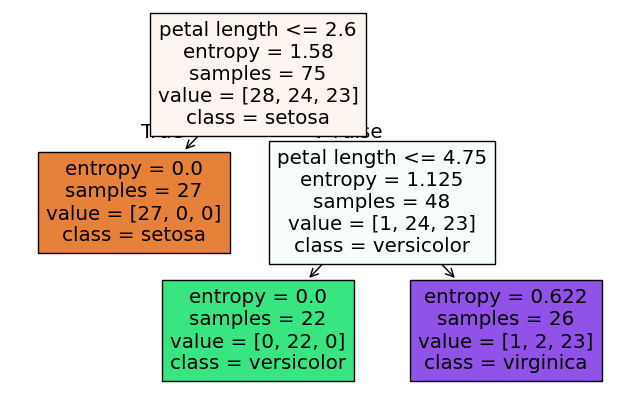

In [46]:
# Step 5 — the final model, and the one look at the test set
model_final = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
model_final.fit(X_train_alt, y_train_alt)

train_err = errors(model_final, X_train_alt, y_train_alt)
test_err = errors(model_final, X_test, y_test)
test_acc = model_final.score(X_test, y_test)

print(f"training errors: {train_err} / {len(y_train_alt)}")
print(f"test errors:     {test_err} / {len(y_test)} -> test accuracy {test_acc:.3f}")

plt.figure(figsize=(8, 5))
plot_tree(model_final, feature_names=X.columns, class_names=iris.target_names, filled=True)
plt.show()


**Answer.**

- **Training vs. Test performance:** The final tree (`max_depth=2`) achieves 3 training errors out of 75 (accuracy 96.0%) and **6 test errors out of 75 (accuracy 92.0%)**.
- **Fidelity of the cross-validation estimate:** The test accuracy (**0.920**) is in close agreement with the cross-validation estimate (**0.960 ± 0.033**), within approximately one standard deviation. Cross-validation provided an honest estimate of generalization without leaking information from the test set.
- **Tree structure:** The tree splits on `petal_length <= 2.6` (isolating class 0, *setosa*) and `petal_width <= 1.65` (separating class 1, *versicolor*, from class 2, *virginica*). The 3 training errors are the 2 conflicting/overlapping samples (flowers 113 and 125) and 1 borderline sample that would require deeper splits to be isolated.


### Why shuffle and stratify? ★

Run `cross_val_score` of a fully grown tree on the **whole** Iris data set (`X`, `y`, which are sorted by class) with
`cv=KFold(3)` — no shuffling — and then with `cv=StratifiedKFold(3, shuffle=True, random_state=SEED)`. Explain the difference.

In [ ]:
# Fully grown tree on the entire Iris dataset (sorted by class)
tree_full = DecisionTreeClassifier(criterion="entropy", random_state=SEED)

# 1. KFold(3) without shuffle
cv_kfold = KFold(n_splits=3, shuffle=False)
scores_kfold = cross_val_score(tree_full, X, y, cv=cv_kfold)

# 2. StratifiedKFold(3) with shuffle
cv_strat = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scores_strat = cross_val_score(tree_full, X, y, cv=cv_strat)

print(f"KFold(3), no shuffle:       {np.round(scores_kfold, 3)}")
print(f"StratifiedKFold(3), shuffle: {np.round(scores_strat, 3)}")


KFold(3), no shuffle:       [0. 0. 0.]
StratifiedKFold(3), shuffle: [1.   0.94 0.94]


**Answer.**

- **Why `KFold(3)` without shuffling yields `[0. 0. 0.]`:**
  The Iris dataset is sorted by class (rows 0–49 are *setosa*, 50–99 *versicolor*, 100–149 *virginica*). Without shuffling, each fold contains only one class. In round 1, Fold 1 has only *setosa*, but the model was trained only on folds 2 and 3 (*versicolor* and *virginica*), so it has never seen *setosa* and gets 0% accuracy. The same occurs for every fold.
- **Why `StratifiedKFold(3, shuffle=True)` works:**
  Shuffling and stratifying guarantees that every fold contains a balanced 1:1:1 proportion of all three classes (~16–17 samples of each class). The model learns all classes in each round and is evaluated on a representative hold-out fold, achieving ~92–100% accuracy.


### A cross-validation estimate also varies ★

Repeat Step 4 for depth 2 and depth 4 with five different `random_state` values of `StratifiedKFold` (e.g. 0 to 4).
How much does the mean change? What does it tell you about comparing two depths whose CV means differ by 0.01?

In [47]:
# Cross-validation variance across different random seeds
means_depth2 = []
means_depth4 = []

for seed in range(5):
    cv_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    score2 = cross_val_score(
        DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED),
        X_train_alt, y_train_alt, cv=cv_seed
    ).mean()
    score4 = cross_val_score(
        DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED),
        X_train_alt, y_train_alt, cv=cv_seed
    ).mean()
    means_depth2.append(score2)
    means_depth4.append(score4)

print("depth 2:", np.round(means_depth2, 3))
print("depth 4:", np.round(means_depth4, 3))


depth 2: [0.96  0.96  0.96  0.96  0.933]
depth 4: [0.933 0.947 0.96  0.947 0.92 ]


**Answer.**

- **Variation of the estimate:** For depth 2, the CV mean fluctuates between **0.933 and 0.960** (range of ~0.027), while for depth 4 it varies between **0.920 and 0.960** (range of ~0.040).
- **Comparing depths that differ by 0.01:**
  A difference of 0.01 (1%) between two depths is smaller than the variance caused simply by how the 75 samples happen to be partitioned into folds (~0.03–0.04). Therefore, a 0.01 gap is within random sampling noise and does not indicate a statistically meaningful difference. Under such ties, the simpler model (`depth=2`) should always be preferred.


# Part B — NordicMart: a churn tree

The customer table of Lecture 6 and Lab 1: 3000 customers, target `churned` (12% churners).
The setup is the same as Lecture 10, so your numbers will appear on Wednesday's slides.

## B1. Features, target, baseline

1. Load the file into `df` (raw table, not modified).
1. Features: `tier`, `age`, `days_since_last_buy`, `annual_spend`, `web_sessions_month`, `tickets_90d`.
   `customer_id` is an identifier, `postcode` is constant (Lab 1): neither is a feature. Target: `churned`.
1. scikit-learn trees need numeric features: code `tier`, which is ordinal, as Basic = 0, Silver = 1, Gold = 2 with
   `.map({...})`. The general treatment of categorical attributes comes in session 16.
1. Missing values stay `NaN`: the tree handles them (see B6). Count them per column.
1. Baseline accuracy?

In [23]:
# your code here


(3000, 6)
tier                     0
age                    303
days_since_last_buy      0
annual_spend             0
web_sessions_month     540
tickets_90d              0
dtype: int64
baseline accuracy ('nobody churns'): 88.0%


## B2. A stratified train/test split

With an imbalanced target a plain random split can, by chance, put a different share of churners in the two parts.
Split 70/30 with `test_size=0.3`, `stratify=yn` and `random_state=SEED`, and check size and churn rate of the two parts.

In [24]:
# your code here


,customers,churners,churn rate
training,2100,252,0.12
test,900,108,0.12


## B3. A fully grown tree

Learn a `DecisionTreeClassifier(random_state=0)` (default criterion: Gini) on the training part.
Print depth and number of leaves, training and test accuracy, and compare with the baseline.
Then show the cross-table of actual vs predicted classes on the test set (`pd.crosstab`, as in Lab 1).

In [25]:
# your code here


depth: 23 | leaves: 289
training accuracy 1.000 | test accuracy 0.824 | baseline 0.880


predicted,0,1
actual,,
0,705,87
1,71,37


**Answer.** *Write your answer here (double-click to edit).*

## B4. Choosing the depth with cross-validation

Use [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html):
like `cross_val_score`, but it returns a dictionary and, with `return_train_score=True`, also the accuracy
on the learning part of each round (`"train_score"`) besides the held-out one (`"test_score"`).

1. Create `cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` (the folds of Lecture 10).
1. For `max_depth` in `[1, 2, 3, 4, 5, 6, 8, 10, 12, None]` record: mean training accuracy, mean and std of the held-out accuracy.
1. Plot the two curves; draw the held-out one with error bars (`ax.errorbar(..., yerr=std)`) and the baseline as a horizontal line.

In [26]:
# your code here


,training,held-out mean,held-out std
max_depth,,,
1,0.881,0.879,0.004
2,0.895,0.887,0.008
3,0.899,0.888,0.008
4,0.906,0.890,0.006
5,0.915,0.886,0.010
6,0.926,0.879,0.013
8,0.944,0.880,0.009
10,0.964,0.863,0.015
12,0.979,0.854,0.017


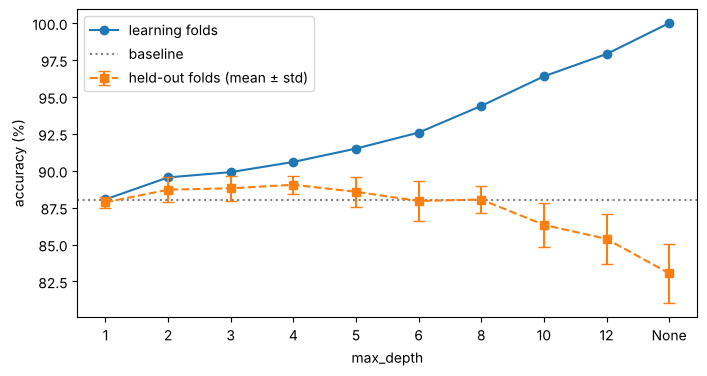

In [27]:
# your code here


**Question.** Which depth does cross-validation choose? How far is it from the baseline? How large is the standard deviation
compared with the differences between depths 2 and 5?

**Answer.** *Write your answer here (double-click to edit).*

## B5. Another hyperparameter: `min_samples_leaf` ★

Keep `max_depth=4` and try `min_samples_leaf` in `[1, 10, 30, 100]` (the minimum number of training customers in a leaf,
one of the meanings of "the data set is small" in Lecture 9). Use the same `cv_n`.

In [28]:
# your code here


min_samples_leaf=  1: 0.8905 ± 0.0062
min_samples_leaf= 10: 0.8876 ± 0.0079
min_samples_leaf= 30: 0.8876 ± 0.0079
min_samples_leaf=100: 0.8819 ± 0.0097


**Answer.** *Write your answer here (double-click to edit).*

## B6. The final model: one test measure, and reading the tree

1. Learn the tree with the chosen depth on the **whole** training part; compute the test accuracy and the cross-table, **once**.
1. Print the first two levels of the tree as text with `export_text(model, feature_names=FEATURES, max_depth=2)`.

In [29]:
# your code here


test accuracy 0.879 | baseline 0.880


predicted,0,1
actual,,
0,768,24
1,85,23


In [30]:
# your code here


|--- days_since_last_buy <= 111.50
|   |--- web_sessions_month <= inf
|   |   |--- annual_spend <= 5778.30
|   |   |   |--- truncated branch of depth 2
|   |   |--- annual_spend >  5778.30
|   |   |   |--- class: 1
|   |--- web_sessions_month >  inf
|   |   |--- days_since_last_buy <= 52.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  52.50
|   |   |   |--- truncated branch of depth 2
|--- days_since_last_buy >  111.50
|   |--- web_sessions_month <= 0.50
|   |   |--- age <= 59.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  59.00
|   |   |   |--- truncated branch of depth 2
|   |--- web_sessions_month >  0.50
|   |   |--- days_since_last_buy <= 733.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  733.50
|   |   |   |--- truncated branch of depth 2



**Questions.**

1. Test accuracy vs CV estimate vs baseline: what do you conclude? How many churners does the tree find?
1. Which attribute is at the root? Does it agree with what EDA suggested in Lab 1?
1. Two tests look strange: `web_sessions_month <= inf` and `days_since_last_buy > 733.50`. What are they doing?
   (Hint: what is in Lab 1's EDA log about missing sessions and the value 999?)

**Answer.** *Write your answer here (double-click to edit).*

## B7. Data leakage: a tree that is too good

Lecture 9, *Route 2*: suppose that somebody added the column `days_since_last_buy_today`, recency measured **today**,
90 days after the snapshot. By definition a churner bought nothing in those 90 days, so for churners this value is
the old recency + 90; for the others it is below 90.

The cell below creates this column in a copy of the features (it simulates the error; do not change it).
Then: repeat the split of B2 on `Xleak`, compute the 5-fold CV accuracy of a depth-4 tree, and print the attribute and threshold of its root
(`model.tree_.feature[0]`, `model.tree_.threshold[0]`).

In [31]:
rng = np.random.default_rng(SEED)
Xleak = Xn.copy()
Xleak["days_since_last_buy_today"] = np.where(yn == 1, Xn["days_since_last_buy"] + 90, rng.integers(1, 91, len(Xn)))

In [32]:
# your code here


CV accuracy 1.000 ± 0.000
root: days_since_last_buy_today <= 90.5


**Answer.** *Write your answer here (double-click to edit).*

## B8. The Lab 1 recodings ★

In Lab 1 we recoded 999 and `age == 0` as missing, with a flag `never_bought`. Apply the same recodings to a copy of
`Xn_train` and compare the CV accuracy at depths 3, 4, 5 with the unrecoded features.

**Question.** These recodings are applied before cross-validation, to all rows: is it a leakage like *Route 1* of Lecture 9?

In [33]:
# your code here


depth 3: raw 0.8881 | recoded 0.8948


depth 4: raw 0.8905 | recoded 0.8919


depth 5: raw 0.8857 | recoded 0.8914


**Answer.** *Write your answer here (double-click to edit).*

## Experiment log

Complete the log (double-click to edit). One row per model you would report; the test column is filled only for the final models.

| Data | Model | How chosen | CV accuracy | Test accuracy |
|---|---|---|---|---|
| *Iris, altered* | *majority class* | *—* | *—* | *33%* |
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw training set of Iris was not modified by the alterations, and that the final models were measured on the test set only once.

In [34]:
# quick self-check
assert y_train.loc[125] == 2 and y_train.loc[113] == 2, "the original Iris training set was modified!"
assert errors(tree_orig, X_train, y_train) == 0
print("original training set untouched")

original training set untouched
